# Analysing latency telemetry

Every response carries an additive breakdown of its round trip, the same numbers in a W3C `Server-Timing` header,
and a record in the telemetry dataset. This notebook checks the identities, reads the header, and compares latency
distributions across twins.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': 'c88add07efb8:7:a77a42',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. The Server-Timing header

Browsers and HTTP tools understand `Server-Timing`; QPUTwin fills it with the main spans of the job.

In [2]:
import httpx
resp = httpx.post(f"{API_URL}/v1/jobs", json=body("quantinuum_helios", ghz(8)))
spans = {part.split(";")[0].strip(): float(part.split("dur=")[1]) for part in resp.headers["server-timing"].split(",")}
print(resp.headers["server-timing"])
pd.Series(spans, name="ms")

total;dur=5.809, validation;dur=0.593, routing;dur=0.029, dispatch;dur=4.482, worker;dur=3.125, qpu;dur=0.831, orchestration;dur=2.600


total            5.809
validation       0.593
routing          0.029
dispatch         4.482
worker           3.125
qpu              0.831
orchestration    2.600
Name: ms, dtype: float64

## 2. The spans add up exactly

Over 50 jobs, the orchestrator and worker spans sum to the reported round trip; the residual is rounding.

In [3]:
records = [run(b, ghz(6), shots=256)["telemetry"] for b in ALL_BACKENDS for _ in range(7)]
b = pd.DataFrame([t["breakdown"] | {"total": t["total_roundtrip_ms"]} for t in records])
top = ["ingress_ms", "validation_ms", "routing_ms", "orchestrator_queue_ms", "network_transit_ms", "worker_service_ms",
       "response_assembly_ms", "unattributed_ms"]
worker = ["worker_queue_ms", "worker_parse_ms", "worker_route_ms", "worker_compile_ms", "simulation_ms", "sampling_ms",
          "worker_unattributed_ms"]
print(f"max |orchestrator spans - total|: {abs(b[top].sum(axis=1) - b['total']).max():.2e} ms")
print(f"max |worker spans - worker service|: {abs(b[worker].sum(axis=1) - b['worker_service_ms']).max():.2e} ms")

max |orchestrator spans - total|: 1.78e-15 ms
max |worker spans - worker service|: 8.88e-16 ms


## 3. Latency distribution per twin

Fifty small jobs per twin. The distributions are tight, and the twins differ by a millisecond or two.

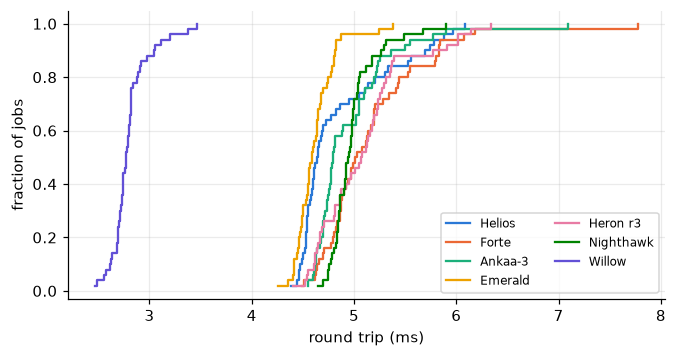

,median ms,p95 ms
Helios,4.64,5.84
Forte,5.02,5.97
Ankaa-3,4.80,5.67
Emerald,4.59,4.85
Heron r3,5.07,6.02
Nighthawk,4.94,5.41
Willow,2.77,3.16


In [4]:
lat = {b: [run(b, ghz(6), shots=256)["telemetry"]["total_roundtrip_ms"] for _ in range(50)] for b in ALL_BACKENDS}
fig, ax = plt.subplots(figsize=(7, 3.4))
for b, xs in lat.items():
    xs = np.sort(xs)
    ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", color=COLORS[b], label=NAMES[b])
ax.set_xlabel("round trip (ms)"); ax.set_ylabel("fraction of jobs"); ax.legend(ncols=2, fontsize=8); plt.show()
pd.DataFrame({NAMES[b]: {"median ms": np.median(x), "p95 ms": np.percentile(x, 95)} for b, x in lat.items()}).T.round(2)

## 4. The telemetry summary endpoint

`GET /v1/telemetry/summary` aggregates the recent records of this orchestrator per backend.

In [5]:
import httpx
summary = httpx.get(f"{API_URL}/v1/telemetry/summary").json()["summary"]
rows = []
for backend, s in summary.items():
    if backend in NAMES and s["metrics"]["total_roundtrip_ms"]["n"]:
        m = s["metrics"]["total_roundtrip_ms"]
        rows.append({"twin": NAMES[backend], "jobs": s["jobs"], "completed": s["completed"], "rejected": s["rejected"],
                     "median ms": m["median"], "p95 ms": m["p95"]})
pd.DataFrame(rows).set_index("twin").round(2)

,jobs,completed,rejected,median ms,p95 ms
twin,,,,,
Willow,83,26,57,11.91,371.53
Heron r3,87,87,0,5.35,39.52
Nighthawk,77,77,0,4.99,62.43
Forte,2410,2410,0,20.07,44.90
Emerald,2518,2518,0,22.09,47.19
Helios,2420,2420,0,20.00,43.50
Ankaa-3,2405,2405,0,25.17,50.68


## 5. Where time goes as circuits grow

For small circuits the service layers dominate; as the circuit grows, simulation takes over.

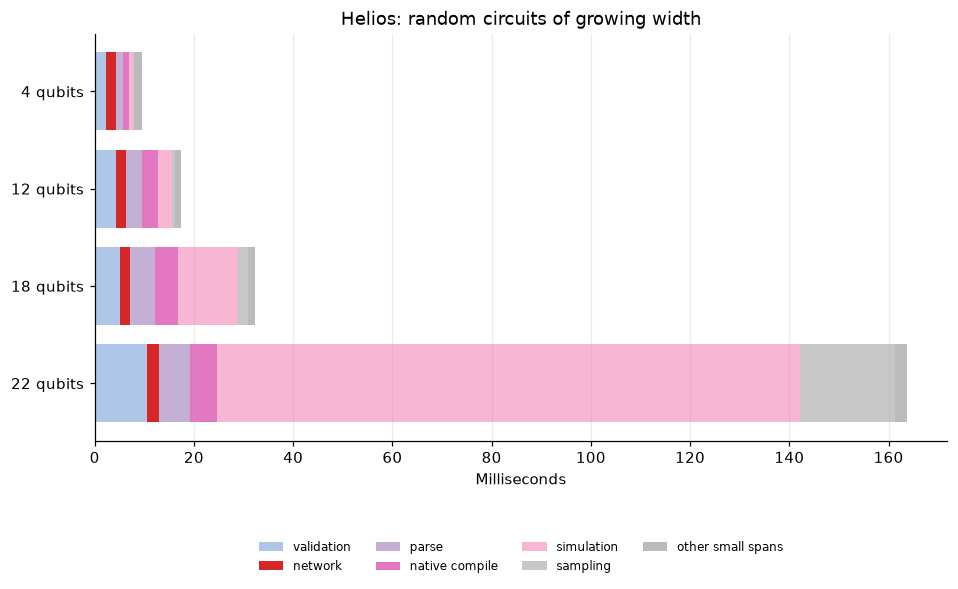

In [6]:
rows = {}
for n in (4, 12, 18, 22):
    t = run("quantinuum_helios", scrambler(n, 6), shots=1024)["telemetry"]
    rows[f"{n} qubits"] = t["breakdown"]
plot_spans(rows, "Helios: random circuits of growing width")

## Takeaways

- The latency breakdown is additive by construction and checkable on every response.
- The same numbers are available as a header, per job, and aggregated per twin.